# Interfaces, Abstraction, and Abstract Base Classes in Python

## The problem: a zoo feeding simulator
A coordinator needs to run a simulated feeding round over a list of animals and collect one description per animal, in order. Different developers implement the lion, panda, and snake.


Adding a compatible animal should not require rewriting the coordinator's loop.


### Learning objectives
- Define an interface from what its caller needs.
- Distinguish abstraction, implementation, and encapsulation.
- Compare duck typing with an abstract base class (ABC).
- Show what an ABC checks and what still needs behavioural tests.
- Validate proposed changes before updating state.


In [1]:
def expect_error(error_type, action):
    """Run a function without arguments and check the expected exception."""
    try:
        action()
    except error_type as error:
        print("Expected error:", type(error).__name__, "-", error)
        return error
    raise AssertionError("The expected exception did not occur")

## 1. First requirement: one operation across several objects
Each initial class has a working method, but the methods have different names. A coordinator cannot call `feed()` uniformly. Predict where the loop fails. The issue is not that these classes contain no abstraction; they lack an agreed operation for this caller.

In [2]:
class InitialLion:
    def feed_lion(self):
        return "Prepare the lion's meal"


class InitialPanda:
    def feed_panda(self):
        return "Prepare the panda's meal"


class InitialSnake:
    def feed_snake(self):
        return "Preparar refeição da snake"


initial_animals = [InitialLion(), InitialPanda(), InitialSnake()]
print(initial_animals[0].feed_lion())
print(initial_animals[1].feed_panda())
print(initial_animals[2].feed_snake())


def try_common_operation():
    for animal in initial_animals:
        animal.feed()


expect_error(AttributeError, try_common_operation)

Prepare the lion's meal
Prepare the panda's meal
Preparar refeição da snake
Expected error: AttributeError - 'InitialLion' object has no attribute 'feed'


AttributeError("'InitialLion' object has no attribute 'feed'")

## 2. Define the interface before choosing inheritance
The interface states what the client can rely on. Here, `feed()` takes no caller arguments, returns non-empty text, and neither prints nor changes state. Returning a value lets the client decide how to display it. With duck typing, the client calls the operation without requiring the objects to share a base class.

In [41]:
class Lion:
    def feed(self):
        return "Prepare the lion's meal"


class Panda:
    def feed(self):
        return "Prepare the panda's meal"


class Snake:
    def feed(self):
        return "Prepare snake's meal"


def run_round(animals):
    results = []
    for animal in animals:
        results.append(animal.feed())
    return results


independent_animals = [Lion(), Panda(), Snake()]
independent_results = run_round(independent_animals)
assert len(independent_results) == 3
for result in independent_results:
    assert isinstance(result, str)
    assert result.strip() != ""
    print(result)

Prepare the lion's meal
Prepare the panda's meal
Prepare snake's meal


### What did that solve?
The coordinator no longer needs species-specific method names. The abstraction is a simulated feeding operation; the species-specific response is an implementation detail.

If an object lacks the operation, that may only become apparent at call time.

An ABC offers a different check for a family of subclasses.

## 3. Abstract Classes to the Rescue

In software engineering, **interfaces** help us manage code more effectively.

They are particularly useful as the codebase grows.

They reduce confusion between similar classes.

With Python interfaces, we can determine which class a programmer should use to solve the current problem.

<br>


***Make a subclass obligation explicit***

We can think of an interface as an `abstract` class that can contain abstract methods and properties.



*   Abstract classes are classes that contain one or more abstract methods
*   An abstract method is a method that is declared but has no implementation.
*   Abstract classes cannot be instantiated and require subclasses to provide implementations for their abstract methods.



How to Define Abstract Classes:

*   Import the `ABC` class from the abc module.
*   Import the `abstractmethod` decorator from the abc module.


*   Make your abstract class a subclass of ABC. This tells the Python interpreter that the class will be an abstract class.
*   Mark a method with the `@abstractmethod` decorator to make it an abstract method.

In [4]:
from abc import ABC, abstractmethod

class AnimalABC(ABC):
    @abstractmethod
    def feed(self):
        raise NotImplementedError("The subclass must provide this operation")


class LionABC(AnimalABC):
    def feed(self):
        return "Prepare the lion's meal"


class IncompletePanda(AnimalABC):
    def feed_panda(self):
        return "Este name não concretiza alimentar"


expect_error(TypeError, AnimalABC)
expect_error(TypeError, IncompletePanda)
lion_abc = LionABC()

assert isinstance(lion_abc, AnimalABC)
assert lion_abc.feed() == "Prepare the lion's meal"

Expected error: TypeError - Can't instantiate abstract class AnimalABC without an implementation for abstract method 'feed'
Expected error: TypeError - Can't instantiate abstract class IncompletePanda without an implementation for abstract method 'feed'


### An incomplete subclass can still be defined
The error occurs at instantiation. A later subclass can complete the implementation, or inherit an already concrete one.

Inheriting from `ABC` alone does not prevent instantiation.

In [28]:
class CompletePanda(IncompletePanda):
    def feed(self):
        return "Prepare the panda's meal"


class SpecializedLion(LionABC):
    pass


class BaseWithoutRequirements(ABC):
    pass


assert CompletePanda().feed() == "Prepare the panda's meal"
assert SpecializedLion().feed() == lion_abc.feed()

concrete_base = BaseWithoutRequirements()
assert isinstance(concrete_base, BaseWithoutRequirements)

print("Concrete implementations can be inherited and reused.")

Concrete implementations can be inherited and reused.


The diagram shows subclass-to-base relationships.

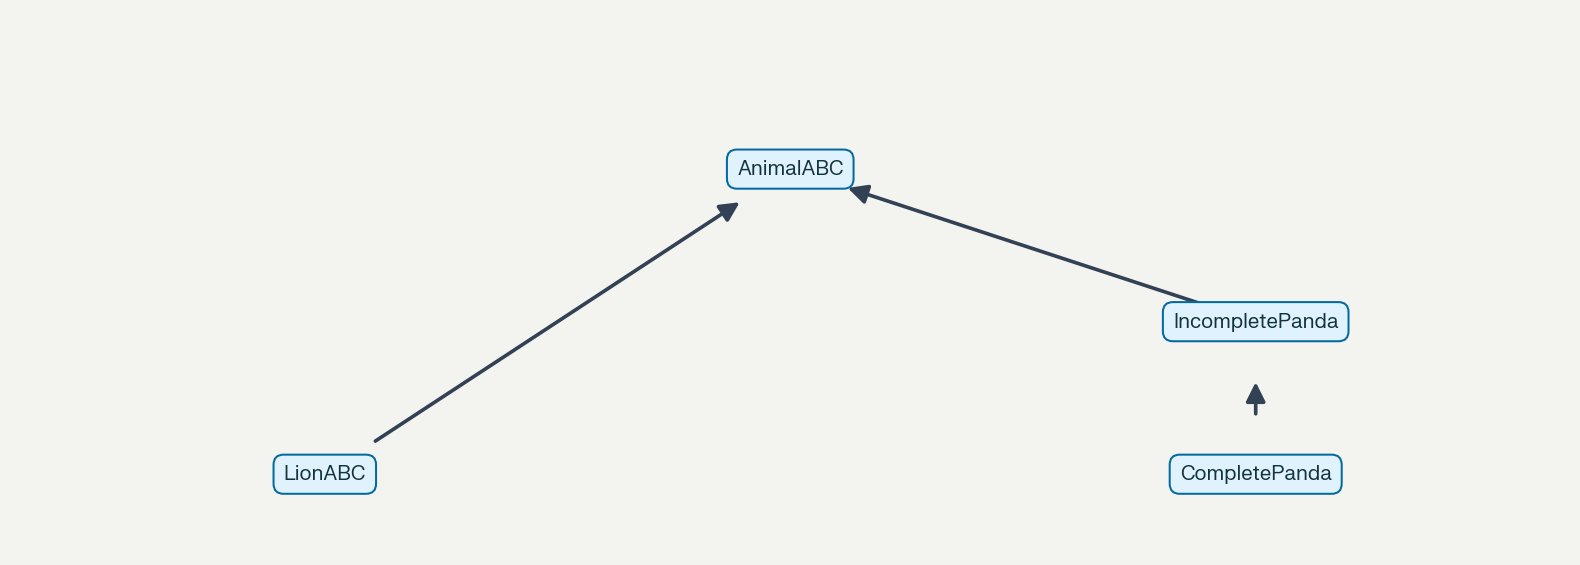

## 4. The client depends on the operation, not the ABC
An unrelated robot can participate if it satisfies the same contract. The loop does not check ancestry. Matching the operation does not itself make the robot a subclass.

In [7]:
class SimulatedRobot:
    def feed(self):
        return "Simulate automated meal delivery"


robot = SimulatedRobot()
assert not isinstance(robot, AnimalABC)
mixed_results = run_round([LionABC(), CompletePanda(), robot])
assert len(mixed_results) == 3
assert mixed_results[2] == "Simulate automated meal delivery"
for result in mixed_results:
    print(result)

Prepare the lion's meal
Prepare the panda's meal
Simulate automated meal delivery


The diagram shows the caller using a common operation.

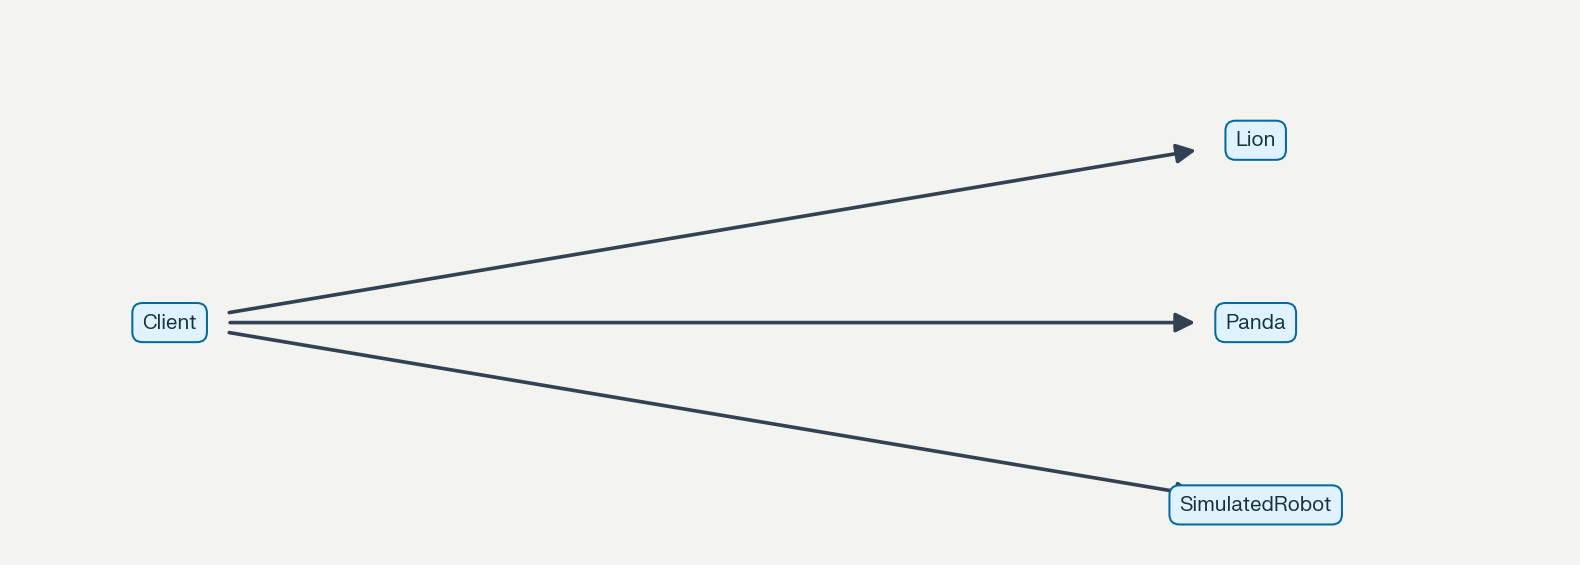

## 5. An ABC does not prove the full contract
An override may resolve an abstract method without accepting the intended arguments. Another override may accept the call but return the wrong value. Predict which example fails at call time and which is detected only by the contract check.

In [33]:
class WrongSignature(AnimalABC):
    def feed(self, quantity):
        return "Quantity: " + str(quantity)


class WrongResult(AnimalABC):
    def feed(self):
        return 42


wrong_signature = WrongSignature()
wrong_result = WrongResult()

expect_error(TypeError, wrong_signature.feed)

assert wrong_result.feed() == 42

def check_initial_contract(animal):
    result = animal.feed()
    assert isinstance(result, str), "O result deve ser texto"
    assert result.strip() != "", "O result não pode ser vazio"


def test_wrong_result():
    check_initial_contract(wrong_result)


expect_error(AssertionError, test_wrong_result)


Expected error: TypeError - WrongSignature.feed() missing 1 required positional argument: 'quantity'
Expected error: AssertionError - O result deve ser texto


AssertionError('O result deve ser texto')

## 6. Abstraction and encapsulation solve different problems
Abstraction lets the caller request a simulated meal without knowing the details. `Encapsulation` controls changes to the selected food. The new requirement is to accept only permitted choices and preserve the previous valid selection after a rejected assignment. The new operation takes a time: `feed(hora)`.

We give the new classes distinct names so both versions remain available.

## 7. Properties and validation
`@property` lets a client read `animal.alimento` through a method. `@alimento.setter` handles assignment. In an abstract property, put `@abstractmethod` immediately above `def`, below `@property`. The setter validates before assigning. The initial value `None` means no selection has been made.

In [39]:
class ScheduledAnimal(ABC):
    def __init__(self, name):
        if not isinstance(name, str) or not name.strip():
            raise ValueError("O name deve ser texto não vazio")
        self.name = name
        self.__food = None

    @property
    @abstractmethod
    def diet(self):
        raise NotImplementedError

    @property
    def food(self):
        return self.__food

    @food.setter
    def food(self, new_food):
        if new_food not in self.diet:
            raise ValueError("Food is not allowed in this simulator")
        self.__food = new_food

    def validate_meal(self, hora):
        if self.__food is None:
            raise ValueError("Select food before running the simulation")
        if not isinstance(hora, str) or not hora.strip():
            raise ValueError("Time must be non-empty text")

    @abstractmethod
    def feed(self, hora):
        raise NotImplementedError


class ScheduledLion(ScheduledAnimal):
    @property
    def diet(self):
        return ("meal-A", "meal-B")

    def feed(self, hora):
        self.validate_meal(hora)
        return self.name + ": simulate " + self.food + " at " + hora


class ScheduledPanda(ScheduledAnimal):
    @property
    def diet(self):
        return ("meal-C", "meal-D")

    def feed(self, hora):
        self.validate_meal(hora)
        return self.name + ": simulate " + self.food + " at " + hora


class ScheduledSnake(ScheduledAnimal):
    @property
    def diet(self):
        return ("meal-E", "meal-F")

    def feed(self, hora):
        self.validate_meal(hora)
        return self.name + ": simulate " + self.food + " at " + hora

### Why this design?
The constructor establishes a known starting state.  An ABC can contain state and concrete behaviour.  A leading underscore marks internal state by convention;

In [40]:
lion = ScheduledLion("Leo")
assert lion.food is None


def feed_without_selection():
    lion.feed("10:00")


expect_error(ValueError, feed_without_selection)
lion.food = "meal-A"
assert lion.feed("10:00") == "Leo: simulate meal-A at 10:00"


def select_invalid_food():
    lion.food = "students :D"


expect_error(ValueError, select_invalid_food)

assert lion.food == "meal-A"
assert lion.feed("10:00") == "Leo: simulate meal-A at 10:00"
print(lion.feed("10:00"))

Expected error: ValueError - Select food before running the simulation
Expected error: ValueError - Food is not allowed in this simulator
Leo: simulate meal-A at 10:00


## 8. A new client for the new contract
Select permitted food before the call. `feed(hora)` then accepts non-empty text, returns a description, and leaves the selection unchanged. Keep setup separate from the client loop so the loop does not need species-specific branches.

In [37]:
panda = ScheduledPanda("Po")
snake = ScheduledSnake("Sam")
panda.food = "meal-C"
snake.food = "meal-E"
scheduled_animals = [lion, panda, snake]


def run_scheduled_round(animals, hora):
    results = []
    for animal in animals:
        results.append(animal.feed(hora))
    return results


scheduled_results = run_scheduled_round(scheduled_animals, "10:30")
assert len(scheduled_results) == 3
for result in scheduled_results:
    assert isinstance(result, str)
    assert result.strip() != ""
    print(result)

Leo: simulate meal-A at 10:30
Po: simulate meal-C at 10:30
Sam: simulate meal-E at 10:30


The third diagram shows how validation prevents rejected input from updating state.

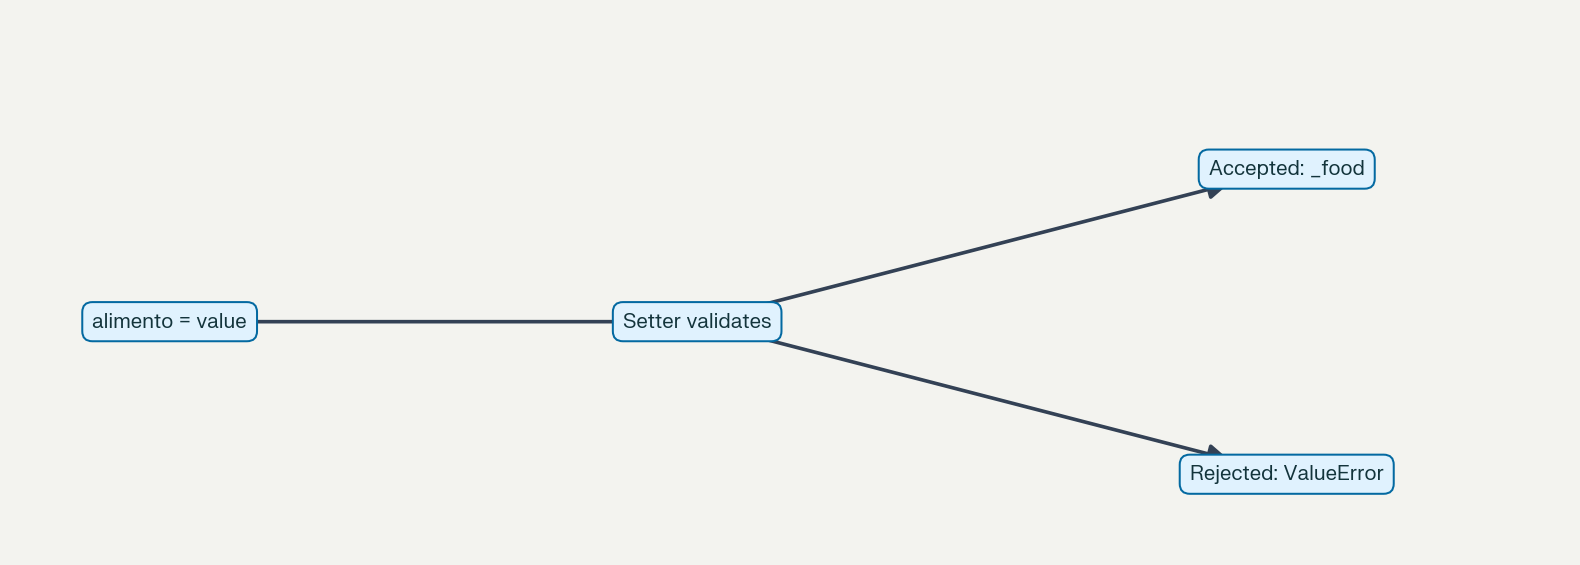

## 9. Transfer the idea: a student list
This second example requires two operations: add a student and look up a name by number. The in-memory implementation rejects duplicate numbers and raises `KeyError` for missing entries. Predict which operation the incomplete class still owes.

In [23]:
class StudentList(ABC):
    @abstractmethod
    def add_student(self, number, name):
        raise NotImplementedError

    @abstractmethod
    def student_name(self, number):
        raise NotImplementedError


class IncompleteStudentList(StudentList):
    def student_name(self, number):
        return "No storage yet"


expect_error(TypeError, IncompleteStudentList)


class InMemoryStudentList(StudentList):
    def __init__(self):
        self._students = {}

    def add_student(self, number, name):
        if type(number) is not int or number <= 0:
            raise ValueError("The number must be a positive integer")
        if not isinstance(name, str) or not name.strip():
            raise ValueError("O name deve ser texto não vazio")
        if number in self._students:
            raise ValueError("Duplicate number")
        self._students[number] = name

    def student_name(self, number):
        return self._students[number]


students = InMemoryStudentList()
students.add_student(1, "Ana")
assert students.student_name(1) == "Ana"


def add_duplicate():
    students.add_student(1, "Bruno")


def look_up_missing():
    students.student_name(99)


expect_error(ValueError, add_duplicate)
expect_error(KeyError, look_up_missing)
assert students.student_name(1) == "Ana"

Expected error: TypeError - Can't instantiate abstract class IncompleteStudentList without an implementation for abstract method 'add_student'
Expected error: ValueError - Duplicate number
Expected error: KeyError - 99


## 10. Abstract methods can contain code
An abstract method may contain reusable implementation. A concrete override can call it with `super()`. The base remains abstract even though the method has a body.

In [24]:
class ReportBase(ABC):
    @abstractmethod
    def generate(self):
        return "Report: "


class StudentReport(ReportBase):
    def generate(self):
        prefix = super().generate()
        return prefix + "students de alunos"


expect_error(TypeError, ReportBase)

assert StudentReport().generate() == "Report: students de alunos"
print(StudentReport().generate())


Expected error: TypeError - Can't instantiate abstract class ReportBase without an implementation for abstract method 'generate'
Report: students de alunos
